# 01 · Data Audit

**Goal:** load the raw Transparency Project files, check them against the codebook, and list every data issue before any analysis.

**Data:** Division on Addiction, *Second Session at the Virtual Poker Table*. Medford, MA: Division on Addiction, The Transparency Project [database distributor], accessed October 21, 2026. Raw files are not included in this repository.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
RAW = ROOT / "data" / "raw"
if not RAW.exists():          # fall back to CSVs in the project root
    RAW = ROOT
DB = ROOT / "data" / "poker.db"
DB.parent.mkdir(exist_ok=True)
con = sqlite3.connect(DB)

def q(sql):
    """Run a SQL query and return a DataFrame."""
    return pd.read_sql_query(sql, con)

## 1. Load the files and compare row counts with the codebook

In [2]:
FILES = {
    "raw_demographics": ("SecondSeshData1Demographics.csv", 5028),
    "raw_cash":         ("SecondSeshData2CashGames.csv", 51763),
    "raw_tourn":        ("SecondSeshData3Tournaments.csv", 82831),
    "raw_deposits":     ("SecondSeshData4Deposits.csv", 295119),
    "raw_withdrawals":  ("SecondSeshData5Withdrawals.csv", 32307),
}
rows = []
for table, (fname, expected) in FILES.items():
    df = pd.read_csv(RAW / fname)
    df.to_sql(table, con, if_exists="replace", index=False)
    rows.append({"table": table, "rows_in_file": len(df), "rows_in_codebook": expected,
                 "difference": len(df) - expected, "players": df["UserID"].nunique()})
pd.DataFrame(rows)

,table,rows_in_file,rows_in_codebook,difference,players
0,raw_demographics,5028,5028,0,5028
1,raw_cash,51763,51763,0,4232
2,raw_tourn,82831,82831,0,3448
3,raw_deposits,295088,295119,-31,5008
4,raw_withdrawals,32307,32307,0,1827


The deposit file is 31 rows short of the codebook (under 0.02%). The cause cannot be identified from the files, so it is documented and the analysis continues.

## 2. Coverage and date ranges

In [3]:
q("""
select 'cash games' as source, min(Date) as first_date, max(Date) as last_date from raw_cash
union all select 'tournaments', min(Date), max(Date) from raw_tourn
union all select 'deposits', min(SummaryDate), max(ProcessDate) from raw_deposits
union all select 'withdrawals', min(SummaryDate), max(ProcessDate) from raw_withdrawals
""")

,source,first_date,last_date
0,cash games,2015-02-01,2020-07-28
1,tournaments,2015-02-01,2021-01-01
2,deposits,2015-02-01,2020-07-15
3,withdrawals,2015-02-01,2020-07-15


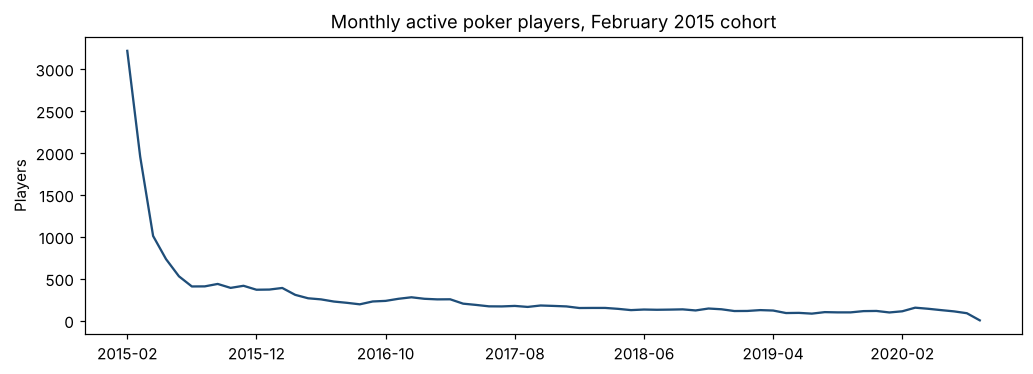

,month,active_players
64,2020-06,109
65,2020-07,87
66,2021-01,2


In [4]:
monthly = q("""
select substr(Date, 1, 7) as month, count(distinct UserID) as active_players
from (select UserID, Date from raw_cash union select UserID, Date from raw_tourn)
group by 1 order by 1
""")
ax = monthly.plot(x="month", y="active_players", figsize=(11, 3.5), legend=False, color="#1f4e79")
ax.set_title("Monthly active poker players, February 2015 cohort")
ax.set_xlabel(""); ax.set_ylabel("Players")
monthly.tail(3)

The original study used February 2015 to January 2017, but activity continues to July 2020. Two tournament rows dated 2021-01-01 sit outside the continuous series.

**Decision:** analyse complete months from February 2015 to June 2020.

## 3. Data quality checks

In [5]:
checks = {
    "Players with missing country": "select count(*) from raw_demographics where CountryID is null",
    "Players with no deposit record": "select count(*) from raw_demographics where UserID not in (select UserID from raw_deposits)",
    "Cash: duplicate player-days": "select count(*) - (select count(*) from (select distinct UserID, Date from raw_cash)) from raw_cash",
    "Cash: all-zero rows": "select count(*) from raw_cash where Windows = 0 and StakesC = 0 and WinningsC = 0",
    "Tournaments: duplicate player-days": "select count(*) - (select count(*) from (select distinct UserID, Date from raw_tourn)) from raw_tourn",
    "Tournaments: rows dated 2021": "select count(*) from raw_tourn where Date >= '2021-01-01'",
    "Deposits: exact duplicate transactions": """select count(*) - (select count(*) from (select distinct UserID, SummaryDate, ProcessDate,
        ProcessTime, PayMeth, PayMethCat, CardType, Amount, Status from raw_deposits)) from raw_deposits""",
    "Deposits: processed before requested": "select count(*) from raw_deposits where ProcessDate < SummaryDate",
    "Deposits: non-positive amounts": "select count(*) from raw_deposits where Amount <= 0",
    "Withdrawals: exact duplicate transactions": """select count(*) - (select count(*) from (select distinct UserID, SummaryDate, ProcessDate,
        ProcessTime, PayMeth, PayMethCat, CardType, Amount, Status from raw_withdrawals)) from raw_withdrawals""",
    "Withdrawals: non-positive amounts": "select count(*) from raw_withdrawals where Amount <= 0",
}
pd.DataFrame([(k, con.execute(v).fetchone()[0]) for k, v in checks.items()], columns=["check", "result"])

,check,result
0,Players with missing country,12
1,Players with no deposit record,20
2,Cash: duplicate player-days,0
3,Cash: all-zero rows,0
4,Tournaments: duplicate player-days,0
5,Tournaments: rows dated 2021,2
6,Deposits: exact duplicate transactions,40
7,Deposits: processed before requested,0
8,Deposits: non-positive amounts,0
9,Withdrawals: exact duplicate transactions,3


## 4. Inconsistent labels

In [6]:
q("select PayMethCat, count(*) as deposits from raw_deposits group by 1 order by 2 desc")

,PayMethCat,deposits
0,EEA debit/credit card,108758
1,eWallet,72943
2,Bank Transfer,58843
3,Voucher,53375
4,ewallet,481
5,Prepaid Cards,318
6,Cards,257
7,Mobile Carrier Billing,110
8,Others,3


In [7]:
q("select coalesce(CardType, '(blank)') as CardType, count(*) as deposits from raw_deposits group by 1 order by 2 desc")

,CardType,deposits
0,Und,180872
1,CCd,50250
2,DCd,49399
3,(blank),9920
4,DCD,2006
5,CCD,2000
6,PP,462
7,Dd,162
8,UND,17


`ewallet` and `eWallet` are the same category, and card types mix upper and lower case. Both are standardized in notebook 02, following the original authors' R code.

## 5. First business signals

In [8]:
q("""
select 'deposit attempts that failed' as metric, round(100.0 * avg(Status = 'F'), 1) as pct from raw_deposits
union all select 'withdrawal requests reversed', round(100.0 * avg(Status = 'R'), 1) from raw_withdrawals
union all select 'withdrawal value reversed', round(100.0 * sum(case when Status = 'R' then Amount end) / sum(Amount), 1) from raw_withdrawals
""")

,metric,pct
0,deposit attempts that failed,24.2
1,withdrawal requests reversed,46.8
2,withdrawal value reversed,55.0


- **About a quarter of deposit attempts fail.** That is lost revenue and a possible churn trigger, so it gets its own payments analysis.
- **Almost half of withdrawal requests are reversed** by the player, who keeps the money in the account to play on.
- Monthly actives drop by about three quarters in the first three months, so early retention is the main story.

## Issues and treatment

| Issue | Size | Treatment |
|---|---|---|
| Deposit file short of codebook | 31 rows | Documented |
| Exact duplicate transactions | 40 deposits, 3 withdrawals | Remove |
| Inconsistent category and card labels | about 5,000 rows | Standardize |
| Missing country | 12 players | Keep, label `Unknown` |
| Stray 2021 tournament rows, partial July 2020 | 2 rows, 1 month | Window ends 2020-06-30 |

## Limitations

- **No rake or house revenue.** Player value is measured with **net deposits**: completed deposits minus completed withdrawals.
- **One registration cohort.** Cohorts are built on first activity, not registration month.
- **Post-2017 completeness is undocumented.** The series is continuous, so it is treated as complete.

In [9]:
con.close()